# Q10: sobrevivência da carreira do político

> **Q10.** Dado certo político, como foi a sobrevivência de sua carreira (linha do tempo de participações, vitórias, derrotas e reeleições)? **[Máximo possível]**

**Recorte:** AM, GO, MA, MT, RS e SE, eleições ordinárias de **2002 a 2024** (o `consulta_cand` mais antigo com título de eleitor). 2026 está no banco, mas fica fora até o TSE publicar o resultado final (`fl_divulgado`).

Este notebook é o **rascunho da interface**: cada seção é um componente do painel (`docs/q10-painel/`). O texto com as decisões e as alternativas está em [`docs/q10-carreira.md`](../docs/q10-carreira.md). As views estão em `sql/07_q10_carreira.sql`.

| Parte | Pergunta que responde | View |
|---|---|---|
| A | Como foi a carreira **deste** político? | `q10_linha_do_tempo`, `q10_carreira` |
| B | Quanto tempo uma carreira dura depois da primeira vitória? | `q10_curva_sobrevivencia` |
| C | Quem se elege tenta de novo? E consegue? | `q10_sobrevivencia` |
| D | Quem sobreviveu mais? Quantas carreiras são longas? | `q10_carreira` |

In [1]:
import os
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd() if (Path.cwd() / "dados").exists() else Path.cwd().parent
os.chdir(ROOT)
con = duckdb.connect(str(ROOT / "dados" / "processed" / "tse.duckdb"), read_only=True)
SAIDA = ROOT / "output" / "q10"
SAIDA.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_rows", 100)
pd.set_option("display.max_colwidth", 200)


def sql(consulta: str) -> pd.DataFrame:
    return con.sql(consulta).df()


# Cores: as do painel da Q10 (docs/q10-painel/modelo.html), as mesmas da Q4 e da Q8.
SUPERFICIE, FUNDO = "#fcfcfb", "#f2f4f7"
TEXTO, TEXTO_2, TEXTO_3, GRADE = "#11161d", "#4a5361", "#7b8594", "#e4e3df"
VITORIA, DERROTA, VERDE = "#2a78d6", "#eb6834", "#1baf7a"
TURMAS = {"VEREADOR": VITORIA, "PREFEITO": DERROTA, "DEPUTADO ESTADUAL": VERDE, "DEPUTADO FEDERAL": TEXTO_2}

plt.rcParams.update(
    {
        "figure.facecolor": SUPERFICIE,
        "axes.facecolor": SUPERFICIE,
        "savefig.facecolor": SUPERFICIE,
        "axes.edgecolor": GRADE,
        "axes.labelcolor": TEXTO_2,
        "xtick.color": TEXTO_2,
        "ytick.color": TEXTO_2,
        "text.color": TEXTO,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "font.size": 10,
        "figure.dpi": 110,
    }
)
ANOS = list(range(2002, 2025, 2))

## 0. A base está certa?

As checagens de `sql/validacao/q10_carreira.sql`. Cada uma deve voltar vazia, salvo as exceções conhecidas anotadas no arquivo:

- **V5:** MT 2018 tem 1 senador eleito, não 2. Selma Arruda foi eleita e cassada; o arquivo a traz como NÃO ELEITO, e a vaga foi para a suplementar de 2020, que fica fora.
- **V10:** 16 eleitos sem título válido (2004, 2012 e 2016) não entram, porque a pessoa é o título.
- **V11:** 235 títulos (0,07%) aparecem com nomes de pessoas diferentes: erro de digitação do TSE, que junta duas carreiras numa só.

In [2]:
arquivo = ROOT / "sql" / "validacao" / "q10_carreira.sql"
# tira os comentários antes de separar as consultas por ";"
texto = "\n".join(
    linha for linha in arquivo.read_text(encoding="utf-8").splitlines() if not linha.lstrip().startswith("--")
)
resultado = []
for consulta in (c for c in texto.split(";") if "SELECT" in c):
    nome = consulta.split("'")[1]
    linhas = con.sql(consulta).fetchall()
    resultado.append({"checagem": nome, "linhas": len(linhas), "situação": "OK" if not linhas else "ver abaixo"})
    if linhas:
        display(pd.DataFrame(linhas).iloc[:, 1:].head(12))
pd.DataFrame(resultado)

,1,2,3,4
0,2018,MT,SENADOR,1


,1,2
0,2004,3
1,2012,9
2,2016,4


,1
0,234


,checagem,linhas,situação
0,V1 pessoa × ano repetido,0,OK
1,V2 participações não fecham,0,OK
2,V3 reeleição sem vitória,0,OK
3,V4 intervalo inválido,0,OK
4,V5 eleitos por UF,1,ver abaixo
5,V6 prefeitos eleitos > 1,0,OK
6,V7 fl_divulgado,0,OK
7,V8 funil da sobrevivência,0,OK
8,V9 curva de sobrevivência,0,OK
9,V10 eleito sem título,3,ver abaixo


In [3]:
# o tamanho da base: candidaturas, pessoas e eleitos por ano
sql("""
    SELECT ano,
           count(*) AS candidaturas,
           count(DISTINCT nr_titulo_eleitoral) AS pessoas,
           count(*) FILTER (WHERE fl_eleito) AS eleitos,
           count(*) FILTER (WHERE fl_reeleito) AS reeleitos,
           count(*) FILTER (WHERE resultado = 'SEM RESULTADO') AS sem_resultado
    FROM q10_candidatura WHERE fl_divulgado GROUP BY ano ORDER BY ano
""")

,ano,candidaturas,pessoas,eleitos,reeleitos,sem_resultado
0,2002,3203,3201,318,0,241
1,2004,77386,77175,12648,0,8288
2,2006,3087,3076,312,155,193
3,2008,74626,74473,12580,4703,9686
4,2010,3726,3690,318,173,765
5,2012,92476,92188,15121,4765,6155
6,2014,4590,4569,330,151,623
7,2016,94465,94256,15185,5580,3907
8,2018,5251,5233,345,138,364
9,2020,109581,109427,15251,5594,2971


---
## A. Um político: a linha do tempo

A interação principal da demonstração: **digitar um nome e ver a carreira**. Cada candidatura vira um ponto, numa faixa por cargo (de vereador, embaixo, a governador, em cima). Assim a "subida" da carreira aparece como uma escada.

- ponto cheio = eleito; contorno laranja = não eleito; tracejado = sem resultado; anel = reeleito;
- em cima de cada ponto, o partido (troca de partido salta à vista).

A busca usa o nome civil (`q10_linha_do_tempo`); o painel também procura pelo nome de urna, que vem do `consulta_cand`.

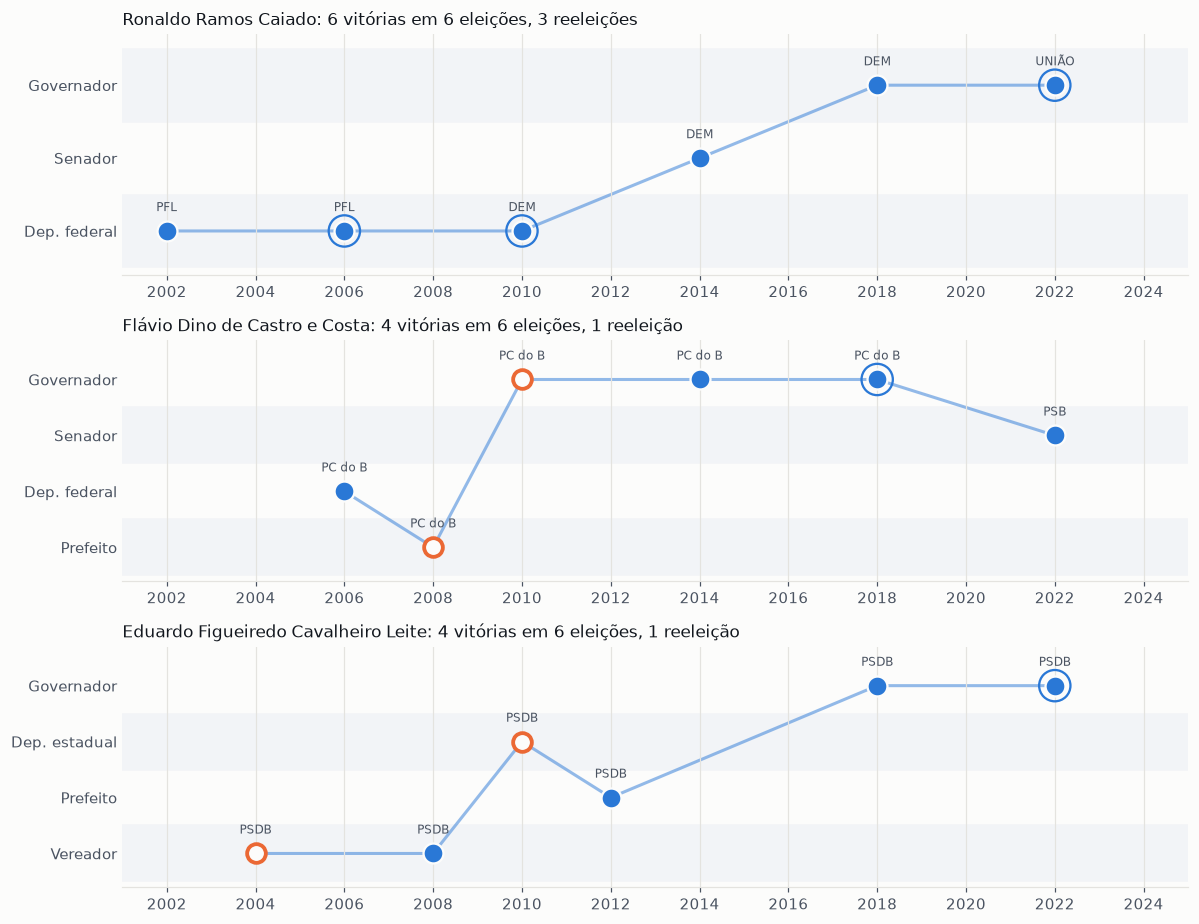

In [4]:
RANK = {13: 0, 12: 1, 11: 2, 7: 3, 8: 3, 6: 4, 9: 5, 10: 5, 4: 5, 5: 6, 3: 7, 2: 8, 1: 9}
FAIXA = {
    0: "Vereador",
    1: "Vice-prefeito",
    2: "Prefeito",
    3: "Dep. estadual",
    4: "Dep. federal",
    5: "Vice / suplente",
    6: "Senador",
    7: "Governador",
    8: "Vice-presidente",
    9: "Presidente",
}


def carreira(nome: str) -> pd.DataFrame:
    """Linha do tempo de quem tem todos os pedaços de `nome` no nome civil (o com mais vitórias)."""
    termos = " AND ".join(f"strip_accents(upper(nm_candidato)) LIKE '%{t}%'" for t in nome.upper().split())
    titulo = con.sql(f"""
        SELECT nr_titulo_eleitoral FROM q10_carreira WHERE {termos}
        ORDER BY qt_vitorias DESC, qt_participacoes DESC LIMIT 1
    """).fetchone()[0]
    return sql(f"""
        SELECT ano, ds_cargo, cd_cargo, nm_ue, sg_uf, sg_partido, resultado, fl_reeleito, fl_tentou_reeleicao
        FROM q10_linha_do_tempo
        WHERE nr_titulo_eleitoral = '{titulo}' AND fl_divulgado ORDER BY ano
    """).assign(
        nm_candidato=con.sql(f"SELECT nm_candidato FROM politico WHERE nr_titulo_eleitoral = '{titulo}'").fetchone()[0]
    )


def escada(df: pd.DataFrame, ax) -> None:
    faixas = sorted({RANK[c] for c in df.cd_cargo})
    y = {f: i for i, f in enumerate(faixas)}
    for i in range(len(faixas)):
        if i % 2 == 0:
            ax.axhspan(i - 0.5, i + 0.5, color=FUNDO, zorder=0)
    xs, ys = df.ano.tolist(), [y[RANK[c]] for c in df.cd_cargo]
    ax.plot(xs, ys, color=VITORIA, alpha=0.5, lw=2, zorder=1)
    for x, yy, r in zip(xs, ys, df.itertuples(), strict=True):
        if r.fl_reeleito:
            ax.scatter(x, yy, s=420, facecolor="none", edgecolor=VITORIA, lw=1.5, zorder=2)
        if r.resultado == "ELEITO":
            ax.scatter(x, yy, s=170, color=VITORIA, edgecolor=SUPERFICIE, lw=1.5, zorder=3)
        elif r.resultado == "NAO ELEITO":
            ax.scatter(x, yy, s=150, facecolor=SUPERFICIE, edgecolor=DERROTA, lw=2.5, zorder=3)
        else:
            ax.scatter(x, yy, s=150, facecolor=SUPERFICIE, edgecolor=TEXTO_3, lw=1.5, ls="--", zorder=3)
        ax.annotate(
            r.sg_partido, (x, yy), xytext=(0, 13), textcoords="offset points", ha="center", fontsize=8, color=TEXTO_2
        )
    ax.set_yticks(range(len(faixas)), [FAIXA[f] for f in faixas])
    ax.set_ylim(-0.6, len(faixas) - 0.3)
    ax.set_xticks(ANOS)
    ax.set_xlim(2001, 2025)
    ax.grid(axis="x", color=GRADE, lw=0.8)
    ax.spines["left"].set_visible(False)
    ax.tick_params(axis="y", length=0)


EXEMPLOS = ["RONALDO RAMOS CAIADO", "FLAVIO DINO DE CASTRO", "EDUARDO FIGUEIREDO CAVALHEIRO LEITE"]
fig, eixos = plt.subplots(len(EXEMPLOS), 1, figsize=(11, 8.5))
for ax, nome in zip(eixos, EXEMPLOS, strict=True):
    df = carreira(nome)
    escada(df, ax)
    v, n, re_ = (df.resultado == "ELEITO").sum(), len(df), df.fl_reeleito.sum()
    nome_proprio = " ".join(
        w if w in ("de", "da", "do", "dos", "das", "e") else w.capitalize() for w in df.nm_candidato[0].lower().split()
    )
    ax.set_title(
        f"{nome_proprio}: {v} vitórias em {n} eleições, {re_} {'reeleição' if re_ == 1 else 'reeleições'}",
        loc="left",
        fontsize=11,
    )
fig.tight_layout()
fig.savefig(SAIDA / "a_escada_exemplos.png", bbox_inches="tight")

In [5]:
# o resumo da carreira, uma linha por pessoa: é o que alimenta os indicadores da parte A
sql("""
    SELECT nm_candidato, ufs, qt_participacoes, qt_vitorias, qt_derrotas, qt_sem_resultado,
           qt_tentativas_reeleicao, qt_reeleicoes, qt_max_vitorias_seguidas, anos_carreira, qt_partidos, trajetoria
    FROM q10_carreira
    WHERE strip_accents(nm_candidato) IN ('RONALDO RAMOS CAIADO', 'FLAVIO DINO DE CASTRO E COSTA', 'EDUARDO FIGUEIREDO CAVALHEIRO LEITE')
""")

,nm_candidato,ufs,qt_participacoes,qt_vitorias,qt_derrotas,qt_sem_resultado,qt_tentativas_reeleicao,qt_reeleicoes,qt_max_vitorias_seguidas,anos_carreira,qt_partidos,trajetoria
0,RONALDO RAMOS CAIADO,[GO],6,6,0,0,3,3,6,20,3,2002 DEPUTADO FEDERAL (PFL) ELEITO → 2006 DEPUTADO FEDERAL (PFL) REELEITO → 2010 DEPUTADO FEDERAL (DEM) REELEITO → 2014 SENADOR (DEM) ELEITO → 2018 GOVERNADOR (DEM) ELEITO → 2022 GOVERNADOR (UNIÃO...
1,EDUARDO FIGUEIREDO CAVALHEIRO LEITE,[RS],6,4,2,0,1,1,3,18,1,2004 VEREADOR (PSDB) NAO ELEITO → 2008 VEREADOR (PSDB) ELEITO → 2010 DEPUTADO ESTADUAL (PSDB) NAO ELEITO → 2012 PREFEITO (PSDB) ELEITO → 2018 GOVERNADOR (PSDB) ELEITO → 2022 GOVERNADOR (PSDB) REEL...
2,FLÁVIO DINO DE CASTRO E COSTA,[MA],6,4,2,0,1,1,3,16,2,2006 DEPUTADO FEDERAL (PC do B) ELEITO → 2008 PREFEITO (PC do B) NAO ELEITO → 2010 GOVERNADOR (PC do B) NAO ELEITO → 2014 GOVERNADOR (PC do B) ELEITO → 2018 GOVERNADOR (PC do B) REELEITO → 2022 SE...


**Como ler:** a escada conta a carreira sem precisar da tabela.

- **Ronaldo Caiado (GO):** 6 vitórias em 6 eleições. Três mandatos seguidos de deputado federal (2 reeleições), senador em 2014, governador em 2018 e reeleito em 2022. A ida a governador em 2018 **não** é reeleição: o cargo mudou. Passou por 3 partidos (PFL → DEM → União), o que se lê nos rótulos.
- **Flávio Dino (MA):** deputado federal em 2006, perde a prefeitura de São Luís em 2008 e o governo em 2010, vence o governo em 2014, é reeleito em 2018 e vai para o Senado em 2022. Duas derrotas seguidas no meio não encerram a carreira.
- **Eduardo Leite (RS):** perde para vereador em 2004 e para deputado estadual em 2010, mas vence vereador em 2008, prefeito de Pelotas em 2012, governador em 2018 e se reelege em 2022. O salto 2012 → 2018 é visível: não tentou a reeleição em Pelotas.

Por isso a escada é melhor que uma lista: derrota, troca de cargo e intervalo sem disputar aparecem na forma do desenho.

---
## B. Curva de sobrevivência

A carreira de uma pessoa só ganha sentido comparada com as outras. A curva acompanha **turmas**: quem venceu a primeira eleição num cargo, e quantos ainda tinham mandato (em qualquer cargo) 4, 8, 12 e 16 anos depois. É a curva de sobrevivência da estatística, com "morte" = ficar sem mandato.

- Só entra quem estreou de 2006 em diante: quem aparece em 2002 ou 2004 pode ter carreira anterior, fora da base.
- Cada ponto usa só as turmas que já chegaram lá: o ponto de +16 anos só tem quem venceu em 2006 ou 2008.
- Duas medidas: **ainda eleito** e **ainda disputando** (mesmo perdendo).

pc_eleitos                   pc_disputando                  
anos_depois               4     8     12    16            4     8     12    16
ds_cargo                                                                      
DEPUTADO ESTADUAL       64.8  46.8  30.0  23.8          94.3  81.7  58.8  52.4
DEPUTADO FEDERAL        66.7  40.0  24.0  18.8          89.5  80.0  68.0  50.0
PREFEITO                47.6   5.3  11.5  10.2          73.8  15.9  27.8  21.6
VEREADOR                42.6  26.7  18.1  13.6          80.1  51.9  37.9  27.6

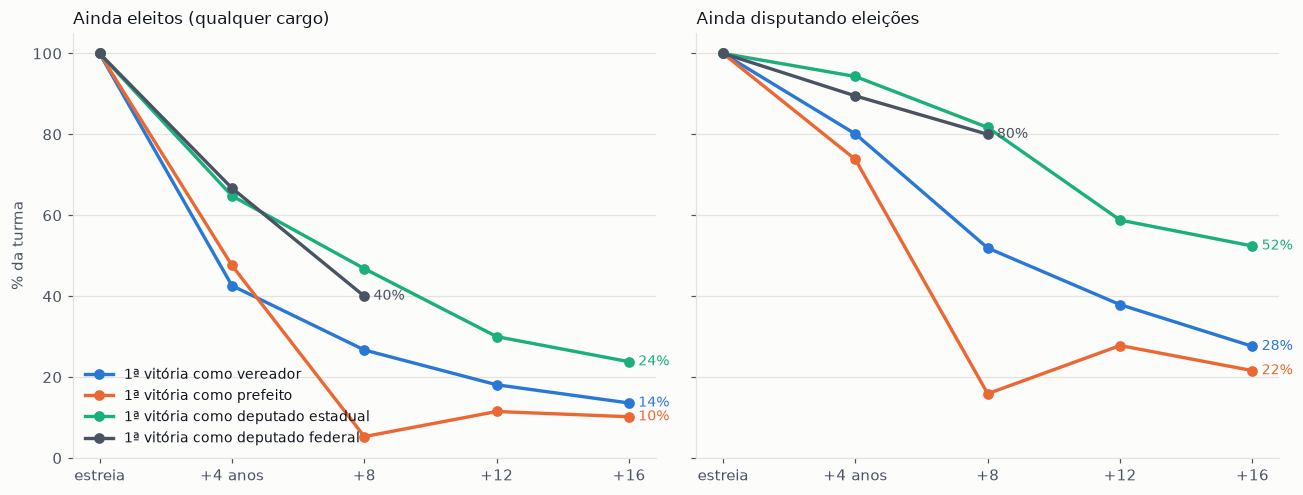

In [6]:
curva = sql("""
    SELECT ds_cargo, anos_depois,
           sum(qt_turma)::INTEGER AS turma,
           sum(qt_ainda_eleitos)::INTEGER AS ainda_eleitos,
           sum(qt_ainda_disputando)::INTEGER AS ainda_disputando
    FROM q10_curva_sobrevivencia GROUP BY ALL ORDER BY ds_cargo, anos_depois
""").assign(
    pc_eleitos=lambda d: (100 * d.ainda_eleitos / d.turma).round(1),
    pc_disputando=lambda d: (100 * d.ainda_disputando / d.turma).round(1),
)

fig, eixos = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
for ax, (col, titulo) in zip(
    eixos,
    [("pc_eleitos", "Ainda eleitos (qualquer cargo)"), ("pc_disputando", "Ainda disputando eleições")],
    strict=True,
):
    for cargo, cor in TURMAS.items():
        d = curva[(curva.ds_cargo == cargo) & (curva.turma >= 30)]
        x, y = [0, *d.anos_depois], [100, *d[col]]
        ax.plot(x, y, marker="o", color=cor, lw=2.2, label=f"1ª vitória como {cargo.lower()}")
        ax.annotate(
            f"{y[-1]:.0f}%",
            (x[-1], y[-1]),
            xytext=(6, 0),
            textcoords="offset points",
            va="center",
            fontsize=9,
            color=cor,
        )
    ax.set_xticks([0, 4, 8, 12, 16], ["estreia", "+4 anos", "+8", "+12", "+16"])
    ax.set_ylim(0, 105)
    ax.set_title(titulo, loc="left", fontsize=11)
    ax.grid(axis="y", color=GRADE, lw=0.8)
eixos[0].set_ylabel("% da turma")
eixos[0].legend(frameon=False, fontsize=9, loc="lower left")
fig.tight_layout()
fig.savefig(SAIDA / "b_curva_sobrevivencia.png", bbox_inches="tight")
curva.pivot(index="ds_cargo", columns="anos_depois", values=["pc_eleitos", "pc_disputando"])

In [7]:
# a mesma curva por UF (vereador, ainda eleito): o filtro de UF do painel
sql("""
    SELECT sg_uf, anos_depois, round(100.0 * sum(qt_ainda_eleitos) / sum(qt_turma), 1) AS pc_ainda_eleitos
    FROM q10_curva_sobrevivencia WHERE cd_cargo = 13 GROUP BY ALL
""").pivot(index="sg_uf", columns="anos_depois", values="pc_ainda_eleitos")

anos_depois,4,8,12,16
sg_uf,,,,
AM,41.3,24.0,13.5,9.6
GO,39.4,25.2,17.6,13.6
MA,46.0,29.6,19.8,11.9
MT,38.6,22.9,16.5,11.7
RS,43.6,27.0,18.2,14.9
SE,46.4,32.2,23.0,18.8


**Como ler:**

- **A maioria das carreiras acaba no primeiro mandato.** De cada 100 vereadores que ganham a primeira eleição, 43 ainda estão eleitos 4 anos depois, 27 depois de 8 e 14 depois de 16.
- **O prefeito despenca aos 8 anos** (48% → 5%): a Constituição permite uma só reeleição seguida, então quem foi reeleito precisa sair ou disputar outro cargo. A curva **sobe** de novo aos 12 anos (12%): é a volta depois do intervalo obrigatório. Esse "degrau" é regra do jogo, não dado ruim, e é o achado mais fácil de explicar na aula.
- **Deputado sobrevive mais:** 65% dos deputados estaduais estreantes ainda têm mandato 4 anos depois. A curva do federal para em +8 anos porque a turma de +12 tem menos de 30 pessoas.
- **Ainda disputando × ainda eleito:** 80% dos vereadores estreantes disputam de novo 4 anos depois, mas só 43% vencem. A distância entre as duas curvas é quem tentou e perdeu.
- **Por UF**, o padrão se repete: Sergipe tem as carreiras mais longas (32% dos vereadores ainda eleitos aos 8 anos) e Mato Grosso as mais curtas (23%).

---
## C. Reeleição: quem se elege tenta de novo? E consegue?

Três números por cargo e ano, de `q10_sobrevivencia`:

- **tentaram:** eleitos que disputaram o mesmo cargo, na mesma cidade ou UF, no ciclo seguinte;
- **reeleitos:** tentaram e venceram;
- **sucesso de quem tentou:** reeleitos ÷ tentaram. Separa "não quis" de "não conseguiu".

Os eleitos de 2022 ficam de fora: a reeleição deles depende de 2026.

,eleitos,tentaram,reeleitos,seguiram,pc_tentaram,pc_reeleitos,pc_sucesso,pc_seguiram
ds_cargo,,,,,,,,
VEREADOR,60948,43742,24694,51679,71.8,40.5,56.5,84.8
PREFEITO,6146,3128,1950,4386,50.9,31.7,62.3,71.4
DEPUTADO ESTADUAL,1050,751,513,980,71.5,48.9,68.3,93.3
DEPUTADO FEDERAL,450,335,244,430,74.4,54.2,72.8,95.6
SENADOR,36,18,10,31,50.0,27.8,55.6,86.1
GOVERNADOR,30,16,9,28,53.3,30.0,56.2,93.3


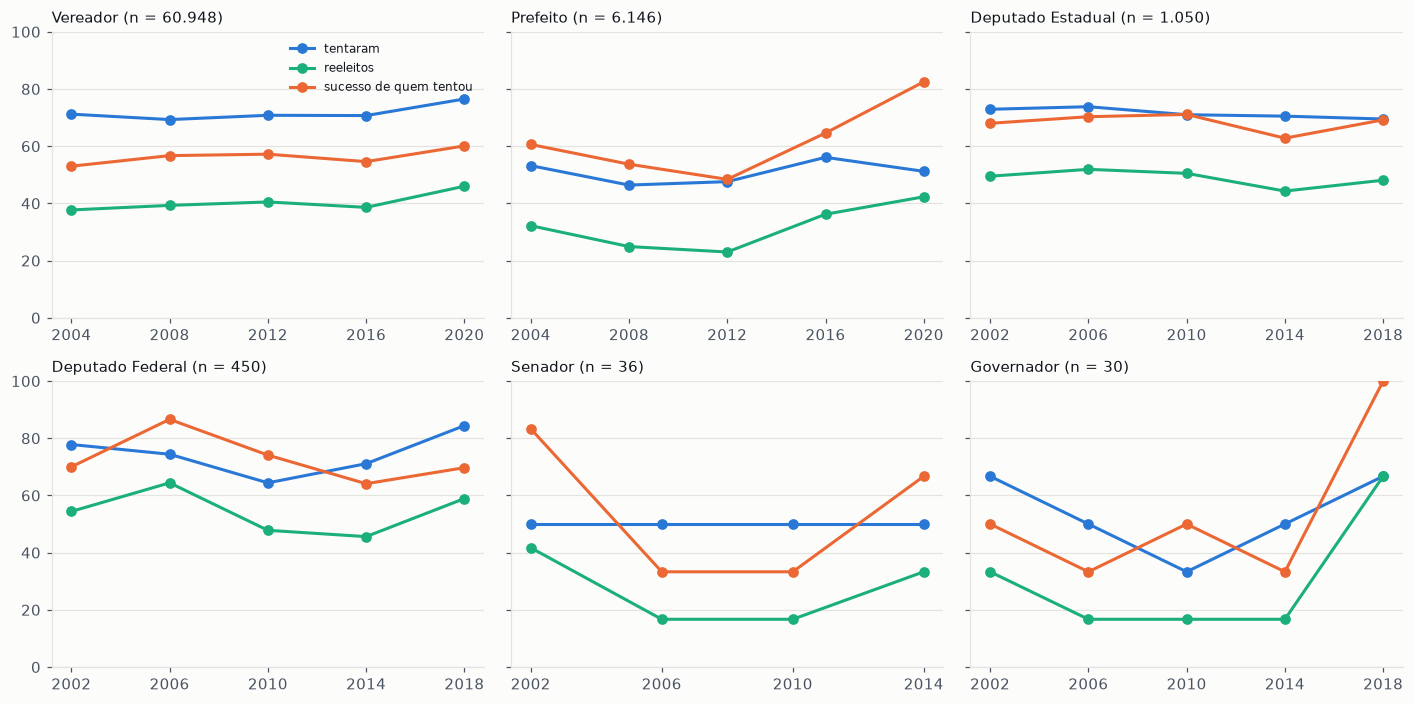

In [8]:
sobrev = sql("""
    SELECT ano, ds_cargo, sum(qt_eleitos)::INTEGER AS eleitos, sum(qt_tentaram_reeleicao)::INTEGER AS tentaram,
           sum(qt_reeleitos)::INTEGER AS reeleitos, sum(qt_seguiram_na_politica)::INTEGER AS seguiram
    FROM q10_sobrevivencia WHERE fl_divulgado GROUP BY ALL ORDER BY ds_cargo, ano
""").assign(
    pc_tentaram=lambda d: (100 * d.tentaram / d.eleitos).round(1),
    pc_reeleitos=lambda d: (100 * d.reeleitos / d.eleitos).round(1),
    pc_sucesso=lambda d: (100 * d.reeleitos / d.tentaram).round(1),
    pc_seguiram=lambda d: (100 * d.seguiram / d.eleitos).round(1),
)

CARGOS_C = ["VEREADOR", "PREFEITO", "DEPUTADO ESTADUAL", "DEPUTADO FEDERAL", "SENADOR", "GOVERNADOR"]
fig, eixos = plt.subplots(2, 3, figsize=(13, 6.5), sharey=True)
for ax, cargo in zip(eixos.flat, CARGOS_C, strict=True):
    d = sobrev[sobrev.ds_cargo == cargo]
    for col, nome, cor in [
        ("pc_tentaram", "tentaram", VITORIA),
        ("pc_reeleitos", "reeleitos", VERDE),
        ("pc_sucesso", "sucesso de quem tentou", DERROTA),
    ]:
        ax.plot(d.ano, d[col], marker="o", color=cor, lw=2, label=nome)
    ax.set_title(f"{cargo.title()} (n = {d.eleitos.sum():,})".replace(",", "."), loc="left", fontsize=10)
    ax.set_xticks(d.ano)
    ax.set_ylim(0, 100)
    ax.grid(axis="y", color=GRADE, lw=0.8)
eixos[0, 0].legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(SAIDA / "c_reeleicao.png", bbox_inches="tight")

# os três números somando todos os anos
sobrev.groupby("ds_cargo")[["eleitos", "tentaram", "reeleitos", "seguiram"]].sum().assign(
    pc_tentaram=lambda d: (100 * d.tentaram / d.eleitos).round(1),
    pc_reeleitos=lambda d: (100 * d.reeleitos / d.eleitos).round(1),
    pc_sucesso=lambda d: (100 * d.reeleitos / d.tentaram).round(1),
    pc_seguiram=lambda d: (100 * d.seguiram / d.eleitos).round(1),
).loc[CARGOS_C]

**Como ler:**

- **Vereador:** 72% dos eleitos tentam de novo, e 57% de quem tenta consegue: no fim, 41% se reelegem. A taxa é estável de 2004 a 2020.
- **Prefeito:** só 51% "tentam", porque quem já está no segundo mandato **não pode** tentar (a view não separa os dois casos; o número de quem podia e não quis é maior). Quem tenta tem 62% de sucesso, e o sucesso cresceu muito: 82% dos prefeitos de 2020 que tentaram se reelegeram em 2024.
- **Deputados:** tentam mais (72% e 74%) e conseguem mais (68% e 73%). Quem chega ao Legislativo estadual ou federal tende a ficar.
- **Senador e governador:** 36 e 30 eleitos nas 6 UFs em 20 anos. As linhas pulam de um ano para o outro por causa do n pequeno; no painel elas ficam, mas o texto não tira conclusão delas.

---
## D. Quem sobreviveu mais? E quantas carreiras são longas?

O ranking é a porta de entrada para a parte A (no painel, clicar numa linha abre a escada). A distribuição ao lado responde à pergunta do agregado: **quantas pessoas continuam depois de N eleições**.

In [9]:
sql("""
    SELECT nm_candidato, ufs, qt_vitorias, qt_participacoes, qt_reeleicoes, anos_carreira, ds_cargo_ultima, trajetoria
    FROM q10_carreira
    ORDER BY qt_vitorias DESC, qt_participacoes DESC, qt_reeleicoes DESC
    LIMIT 15
""")

,nm_candidato,ufs,qt_vitorias,qt_participacoes,qt_reeleicoes,anos_carreira,ds_cargo_ultima,trajetoria
0,PEDRO FERNANDES RIBEIRO,[MA],7,8,4,22,PREFEITO,2002 DEPUTADO FEDERAL (PFL) ELEITO → 2006 DEPUTADO FEDERAL (PTB) REELEITO → 2008 PREFEITO (PTB) NAO ELEITO → 2010 DEPUTADO FEDERAL (PTB) REELEITO → 2014 DEPUTADO FEDERAL (PTB) REELEITO → 2018 1º S...
1,RIGO ALBERTO TELIS DE SOUSA,[MA],7,7,5,22,PREFEITO,2002 DEPUTADO ESTADUAL (PFL) ELEITO → 2006 DEPUTADO ESTADUAL (PSDB) REELEITO → 2010 DEPUTADO ESTADUAL (PV) REELEITO → 2014 DEPUTADO ESTADUAL (PV) REELEITO → 2018 DEPUTADO ESTADUAL (PV) REELEITO → ...
2,JOSE RICARDO WENDLING,[AM],6,11,2,22,VEREADOR,2002 DEPUTADO ESTADUAL (PT) NAO ELEITO → 2004 VEREADOR (PT) ELEITO → 2006 DEPUTADO ESTADUAL (PT) NAO ELEITO → 2008 VEREADOR (PT) REELEITO → 2010 DEPUTADO ESTADUAL (PT) ELEITO → 2014 DEPUTADO ESTAD...
3,ANTONIO ROBERTO OTONI GOMIDE,[GO],6,11,2,22,PREFEITO,2002 DEPUTADO ESTADUAL (PT) NAO ELEITO → 2004 VEREADOR (PT) ELEITO → 2006 DEPUTADO ESTADUAL (PT) NAO ELEITO → 2008 PREFEITO (PT) ELEITO → 2012 PREFEITO (PT) REELEITO → 2014 GOVERNADOR (PT) NAO ELE...
4,JOSENITO VITALE DE JESUS,[SE],6,10,5,22,VEREADOR,2002 DEPUTADO ESTADUAL (PSB) NAO ELEITO → 2004 VEREADOR (PRONA) ELEITO → 2008 VEREADOR (DEM) REELEITO → 2010 DEPUTADO ESTADUAL (DEM) NAO ELEITO → 2012 VEREADOR (DEM) REELEITO → 2014 DEPUTADO ESTAD...
5,CLECIO ANTONIO ALVES,[GO],6,10,4,18,DEPUTADO ESTADUAL,2004 VEREADOR (PT) ELEITO → 2006 DEPUTADO ESTADUAL (PMDB) NAO ELEITO → 2008 VEREADOR (PMDB) REELEITO → 2010 DEPUTADO ESTADUAL (PMDB) NAO ELEITO → 2012 VEREADOR (PMDB) REELEITO → 2014 DEPUTADO ESTA...
6,SEBASTIÃO DE ARAÚJO MELO,[RS],6,10,2,22,PREFEITO,2002 DEPUTADO ESTADUAL (PMDB) NAO ELEITO → 2004 VEREADOR (PMDB) ELEITO → 2006 DEPUTADO ESTADUAL (PMDB) NAO ELEITO → 2008 VEREADOR (PMDB) REELEITO → 2010 DEPUTADO ESTADUAL (PMDB) NAO ELEITO → 2012 ...
7,MARIA DO ROSARIO NUNES,[RS],6,9,5,22,PREFEITO,2002 DEPUTADO FEDERAL (PT) ELEITO → 2004 VICE-PREFEITO (PT) SEM RESULTADO → 2006 DEPUTADO FEDERAL (PT) REELEITO → 2008 PREFEITO (PT) NAO ELEITO → 2010 DEPUTADO FEDERAL (PT) REELEITO → 2014 DEPUTAD...
8,ALOÍSIO BAMBERG,[RS],6,9,5,20,VEREADOR,2004 VEREADOR (PSDB) ELEITO → 2008 VEREADOR (PSDB) REELEITO → 2010 DEPUTADO FEDERAL (PSDB) SEM RESULTADO → 2012 VEREADOR (PPL) REELEITO → 2014 DEPUTADO ESTADUAL (PPL) NAO ELEITO → 2016 VEREADOR (P...
9,JOSE IRAN BARBOSA FILHO,[SE],6,9,1,20,VEREADOR,2004 VEREADOR (PT) ELEITO → 2006 DEPUTADO FEDERAL (PT) ELEITO → 2010 DEPUTADO FEDERAL (PT) NAO ELEITO → 2012 VEREADOR (PT) ELEITO → 2014 DEPUTADO FEDERAL (PT) NAO ELEITO → 2016 VEREADOR (PT) REELE...


,n,pessoas,pessoas_com_vitoria,pc_pessoas_ate_n,pc_disputaram_n_ou_mais
0,1,239061,9527,67.3,100.0
1,2,65459,14317,85.7,32.7
2,3,26718,11464,93.2,14.3
3,4,13166,7949,96.9,6.8
4,5,6457,4626,98.8,3.1
5,6,3498,2809,99.7,1.2
6,7,554,408,99.9,0.3
7,8,215,143,100.0,0.1
8,9,90,61,100.0,0.0
9,10,41,26,100.0,0.0


,n,pessoas,pc_venceram_n_ou_mais
0,1,29230,100.0
1,2,12890,43.1
2,3,5562,18.0
3,4,2465,7.1
4,5,913,2.3
5,6,285,0.6
6,7,2,0.0


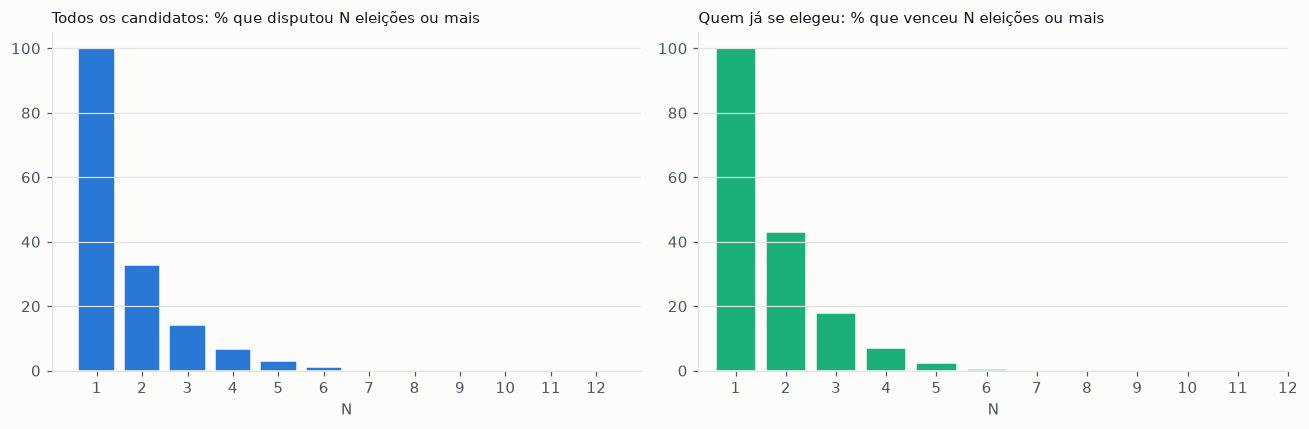

In [10]:
dist = sql("""
    SELECT qt_participacoes AS n, count(*) AS pessoas,
           count(*) FILTER (WHERE qt_vitorias > 0) AS pessoas_com_vitoria
    FROM q10_carreira GROUP BY 1 ORDER BY 1
""")
dist["pc_pessoas_ate_n"] = (100 * dist.pessoas.cumsum() / dist.pessoas.sum()).round(1)
# "sobrevivência" no sentido da issue #35: quantos chegam a disputar pelo menos N eleições
dist["pc_disputaram_n_ou_mais"] = (100 * dist.pessoas[::-1].cumsum()[::-1] / dist.pessoas.sum()).round(1)
vit = sql("SELECT qt_vitorias AS n, count(*) AS pessoas FROM q10_carreira WHERE qt_vitorias > 0 GROUP BY 1 ORDER BY 1")
vit["pc_venceram_n_ou_mais"] = (100 * vit.pessoas[::-1].cumsum()[::-1] / vit.pessoas.sum()).round(1)

fig, eixos = plt.subplots(1, 2, figsize=(12, 4))
eixos[0].bar(dist.n, dist.pc_disputaram_n_ou_mais, color=VITORIA, edgecolor=SUPERFICIE)
eixos[0].set_title("Todos os candidatos: % que disputou N eleições ou mais", loc="left", fontsize=10)
eixos[1].bar(vit.n, vit.pc_venceram_n_ou_mais, color=VERDE, edgecolor=SUPERFICIE)
eixos[1].set_title("Quem já se elegeu: % que venceu N eleições ou mais", loc="left", fontsize=10)
for ax in eixos:
    ax.set_xticks(range(1, 13))
    ax.set_xlabel("N")
    ax.grid(axis="y", color=GRADE, lw=0.8)
fig.tight_layout()
fig.savefig(SAIDA / "d_distribuicao.png", bbox_inches="tight")
display(dist)
vit

**Como ler:**

- **Carreira longa é rara.** De todos os 355 mil candidatos de 2002 a 2024, 67% disputaram uma única eleição; só 14% chegaram a 3 eleições, e 1,2% a 6 ou mais.
- **Entre quem já se elegeu**, 43% venceram 2 eleições ou mais, 7% venceram 4 ou mais e só 0,6% venceram 6 ou mais.
- O topo do ranking (Pedro Fernandes e Rigo Teles, do MA, com 7 vitórias) são deputados que viraram prefeitos: a carreira mais longa costuma passar pelos dois níveis, municipal e estadual, e por isso só aparece porque a base junta eleições gerais e municipais.

---
## O que vai para o painel

| Parte | Componente | Interação na demonstração |
|---|---|---|
| A | busca por nome + escada da carreira + 6 indicadores + tabela | digitar um nome; atalhos (Caiado, Flávio Dino, Eduardo Leite) |
| B | curva de sobrevivência, 4 turmas, "ainda eleito" × "ainda disputando" | alternar a medida; filtro de UF |
| C | tentaram × reeleitos × sucesso, por ano | trocar o cargo (vereador → governador) |
| D | ranking das carreiras mais longas | ordenar por vitórias, anos ou reeleições; clicar abre a parte A |

As alternativas consideradas para cada parte e por que ficamos com estas estão em [`docs/q10-carreira.md`](../docs/q10-carreira.md).